In [1]:
# Cài đặt unrar nếu chưa có
!apt-get install unrar

# Giải nén file vào thư mục hiện tại (/content/)
!unrar x skin-disease-datasaet.rar /content/

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from skin-disease-datasaet.rar

Creating    /content/skin-disease-datasaet                            OK
Creating    /content/skin-disease-datasaet/test_set                   OK
Creating    /content/skin-disease-datasaet/test_set/BA- cellulitis    OK
Extracting  /content/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (1).webp       0%  OK 
Extracting  /content/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (104).jpg       0%  OK 
Extracting  /content/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (106).jpg       0%  OK 
Extracting  /content/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (115).jpg       0%

In [7]:
# 1. Tạo thư mục có tên tương ứng (ví dụ: output_pseudo_masks_HSV_SAM)
import os
output_folder = '/content/output_pseudo_masks_HSV_SAM'
os.makedirs(output_folder, exist_ok=True)

# 2. Giải nén file .zip trực tiếp vào thư mục vừa tạo
!unzip -o output_pseudo_masks_HSV_SAM.zip -d {output_folder}

Archive:  output_pseudo_masks_HSV_SAM.zip
   creating: /content/output_pseudo_masks_HSV_SAM/BA- cellulitis/
   creating: /content/output_pseudo_masks_HSV_SAM/BA-impetigo/
   creating: /content/output_pseudo_masks_HSV_SAM/FU-athlete-foot/
   creating: /content/output_pseudo_masks_HSV_SAM/FU-nail-fungus/
   creating: /content/output_pseudo_masks_HSV_SAM/FU-ringworm/
   creating: /content/output_pseudo_masks_HSV_SAM/PA-cutaneous-larva-migrans/
   creating: /content/output_pseudo_masks_HSV_SAM/VI-chickenpox/
   creating: /content/output_pseudo_masks_HSV_SAM/VI-shingles/
  inflating: /content/output_pseudo_masks_HSV_SAM/VI-chickenpox/167_VI-chickenpox (12)_mask.png  
  inflating: /content/output_pseudo_masks_HSV_SAM/VI-chickenpox/18_VI-chickenpox (1)_mask.png  
  inflating: /content/output_pseudo_masks_HSV_SAM/VI-chickenpox/68_VI-chickenpox (3)_mask.png  
  inflating: /content/output_pseudo_masks_HSV_SAM/VI-chickenpox/22_VI-chickenpox (24)_mask.png  
  inflating: /content/output_pseudo_mask

In [6]:
import os
import shutil

# Danh sách các thư mục bạn muốn xóa
folders = ['PA-cutaneous-larva-migrans', 'VI-chickenpox', 'VI-shingles'] # Thêm tên các thư mục vào đây

for folder in folders:
    folder_path = os.path.join('/content', folder)
    if os.path.exists(folder_path):
        shutil.rmtree(folder_path)
        print(f"Đã xóa: {folder}")

print("Đã dọn dẹp xong!")

Đã xóa: PA-cutaneous-larva-migrans
Đã xóa: VI-chickenpox
Đã xóa: VI-shingles
Đã dọn dẹp xong!


In [8]:
import os
import cv2
import random
import matplotlib.pyplot as plt
from glob import glob
import numpy as np
from fontTools.misc.cython import returns
from tqdm import tqdm
import keras.backend as K
import time
import random
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.layers import SeparableConv2D, BatchNormalization, Activation
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D,Add, MaxPooling2D, Conv2DTranspose, concatenate,DepthwiseConv2D
from tensorflow.keras.optimizers import Adam

In [9]:
# ===============================
# CẤU HÌNH
# ===============================
DATA_DIR = '/content/skin-disease-datasaet/train_set'  # ảnh gốc
MASK_DIR = '/content/output_pseudo_masks_HSV_SAM'      # mask đã tạo HSV + SAM
LABELS = [
    "BA- cellulitis", "BA-impetigo", "FU-athlete-foot", "FU-nail-fungus",
    "FU-ringworm", "PA-cutaneous-larva-migrans", "VI-chickenpox", "VI-shingles"
]

In [10]:
# ===============================
# 🎯 LẤY NGẪU NHIÊN 1 ẢNH MỖI CLASS
# ===============================
sample_per_class = {}
for label in LABELS:
    class_dir = os.path.join(DATA_DIR, label)
    if not os.path.isdir(class_dir):
        print(f"⚠️ Không tìm thấy thư mục: {class_dir}")
        continue

    image_files = glob(os.path.join(class_dir, "**", "*.*"), recursive=True)
    image_files = [f for f in image_files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if not image_files:
        continue

    chosen_path = random.choice(image_files)
    sample_per_class[label] = chosen_path

print(f"✅ Đã chọn {len(sample_per_class)} ảnh đại diện cho các lớp.")

✅ Đã chọn 8 ảnh đại diện cho các lớp.


✅ Đã chọn 8 ảnh đại diện để hiển thị.


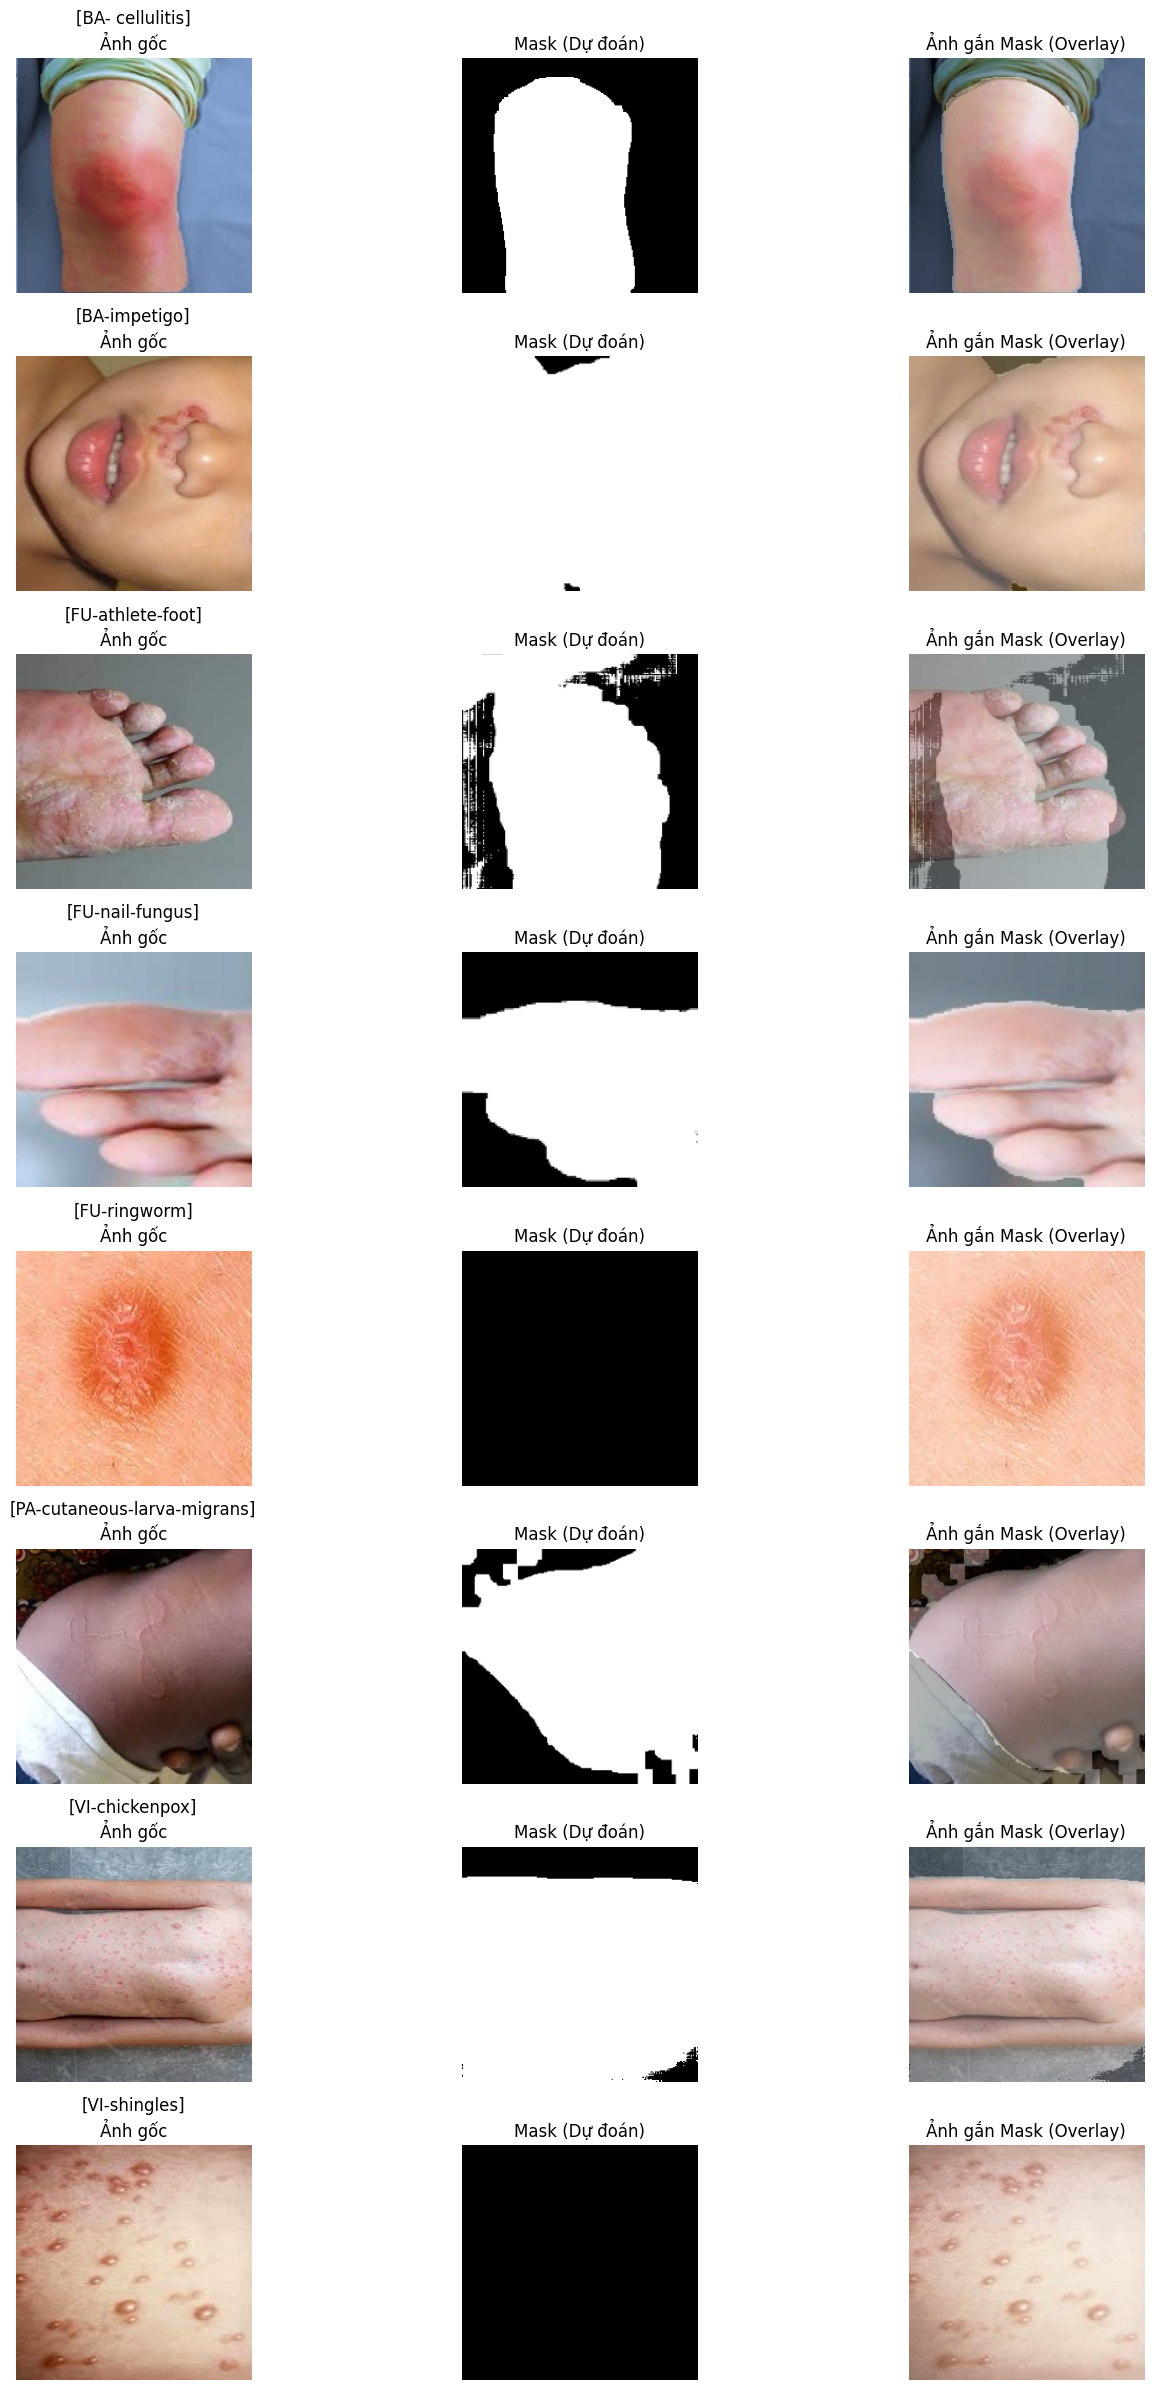

In [11]:
# ===============================
# 🎯 LẤY NGẪU NHIÊN 1 ẢNH MỖI CLASS ĐỂ VIEW
# ===============================
sample_per_class = {}
for label in LABELS:
    class_dir = os.path.join(DATA_DIR, label)
    if not os.path.isdir(class_dir):
        continue

    image_files = glob(os.path.join(class_dir, "**", "*.*"), recursive=True)
    image_files = [f for f in image_files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if not image_files:
        continue

    chosen_path = random.choice(image_files)
    sample_per_class[label] = chosen_path

print(f"✅ Đã chọn {len(sample_per_class)} ảnh đại diện để hiển thị.")

# ===============================
# 🖼️ HIỂN THỊ: ẢNH GỐC | MASK | OVERLAY
# ===============================
plt.figure(figsize=(15, len(sample_per_class) * 3))

for i, (class_name, img_path) in enumerate(sample_per_class.items()):
    # 1. Đọc ảnh gốc
    img = cv2.imread(img_path)
    if img is None:
        continue
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 2. Tìm file mask tương ứng
    img_name = os.path.splitext(os.path.basename(img_path))[0]
    # Lưu ý cách đặt tên file mask lúc lưu (_mask.png)
    mask_path = os.path.join(MASK_DIR, class_name, f"{img_name}_mask.png")

    if not os.path.exists(mask_path):
        print(f"⚠️ Không tìm thấy mask cho: {img_name}")
        continue

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    # Đảm bảo kích thước ảnh gốc và mask khớp nhau
    if mask.shape[:2] != img_rgb.shape[:2]:
        mask = cv2.resize(mask, (img_rgb.shape[1], img_rgb.shape[0]))

    # Chuyển mask sang RGB để làm hiệu ứng chồng (overlay)
    mask_rgb = cv2.cvtColor(mask, cv2.COLOR_GRAY2RGB)

    # Tạo ảnh chồng mask (Overlay): 70% ảnh gốc + 30% mask
    overlay = cv2.addWeighted(img_rgb, 0.7, mask_rgb, 0.3, 0)

    # --- Vẽ lên biểu đồ ---
    # Cột 1: Ảnh gốc
    plt.subplot(len(sample_per_class), 3, i * 3 + 1)
    plt.imshow(img_rgb)
    plt.title(f"[{class_name}]\nẢnh gốc")
    plt.axis("off")

    # Cột 2: Mask trắng đen
    plt.subplot(len(sample_per_class), 3, i * 3 + 2)
    plt.imshow(mask, cmap='gray')
    plt.title("Mask (Dự đoán)")
    plt.axis("off")

    # Cột 3: Ảnh đã được gắn mask (Overlay)
    plt.subplot(len(sample_per_class), 3, i * 3 + 3)
    plt.imshow(overlay)
    plt.title("Ảnh gắn Mask (Overlay)")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# HÀM ĐÁNH GIÁ (METRICS)
# ============================================================
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)


def iou_score(y_true, y_pred, smooth=1e-6):
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

In [13]:
IMAGE_SIZE = 128

def load_dataset(image_dir, mask_dir, image_size=IMAGE_SIZE):
    X, Y = [], []
    all_images = glob(os.path.join(image_dir, "*", "*.*"))
    all_images = [f for f in all_images if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    for path in tqdm(all_images, desc="Đang tải dataset"):
        try:
            # 1. Xác định tên lớp và tên file mask trước
            class_name = os.path.basename(os.path.dirname(path))
            img_name = os.path.splitext(os.path.basename(path))[0]
            mask_path = os.path.join(mask_dir, class_name, f"{img_name}_mask.png")

            # 2. Kiểm tra nếu mask không tồn tại thì bỏ qua ngay (tránh lệch mảng X và Y)
            if not os.path.exists(mask_path):
                continue

            # 3. Đọc ảnh gốc
            img = cv2.imread(path)
            if img is None:
                continue

            # 4. Đọc mask
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            if mask is None:
                continue

            # 5. Resize và chuẩn hóa đồng bộ
            img = cv2.resize(img, (image_size, image_size)) / 255.0
            mask = cv2.resize(mask, (image_size, image_size)) / 255.0
            mask = np.expand_dims(mask, axis=-1)

            # 6. Chỉ append khi cả ảnh và mask đều hợp lệ
            X.append(img)
            Y.append(mask)

        except Exception as e:
            print(f"Lỗi khi xử lý {path}: {e}")
            continue

    return np.array(X), np.array(Y)

# Gọi lại hàm load sau khi đã sửa
X, Y = load_dataset(DATA_DIR, MASK_DIR) # Lưu ý trỏ đúng tên thư mục mask của bạn
print(f"✅ Dataset hoàn tất: X shape: {X.shape}, Y shape: {Y.shape}")

Đang tải dataset: 100%|██████████| 924/924 [00:01<00:00, 901.12it/s]


✅ Dataset hoàn tất: X shape: (856, 128, 128, 3), Y shape: (856, 128, 128, 1)


In [14]:
# ==================================================
# ✂️ Chia dữ liệu Train / Validation
# ==================================================
from sklearn.model_selection import train_test_split

X_train, X_val, Y_train, Y_val = train_test_split(X, Y, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape}, Val: {X_val.shape}")


Train: (684, 128, 128, 3), Val: (172, 128, 128, 3)


In [15]:
# ==================================================
# XÂY DỰNG MÔ HÌNH
# ==================================================
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D,Add, MaxPooling2D, Conv2DTranspose, concatenate,DepthwiseConv2D
from tensorflow.keras.optimizers import Adam


def Unet_optimize(input_size=(128, 128, 3)):
    inputs = Input(input_size)

    def hybrid_block(x, filters):
        # 1. Conv chuẩn cho đặc trưng cục bộ
        x = Conv2D(filters, 3, padding='same', use_bias=False)(x)
        x = BatchNormalization()(x)
        x = Activation('relu')(x)

        # 2. DepthwiseConv để giảm tham số và mở rộng receptive field
        x = DepthwiseConv2D(5, padding='same', use_bias=False)(x)
        x = BatchNormalization()(x)
        x = Activation('relu')(x)

        # 3. PointwiseConv để trộn kênh
        x = Conv2D(filters, 1, padding='same', use_bias=False)(x)
        x = BatchNormalization()(x)
        x = Activation('relu')(x)
        return x

    # --- 🔹 Encoder ---
    c1 = hybrid_block(inputs, 32)
    p1 = MaxPooling2D((2, 2))(c1)

    c2 = hybrid_block(p1, 64)
    p2 = MaxPooling2D((2, 2))(c2)

    c3 = hybrid_block(p2, 128)
    p3 = MaxPooling2D((2, 2))(c3)

    c4 = hybrid_block(p3, 256)
    p4 = MaxPooling2D((2, 2))(c4)

    # --- 🔹 Bottleneck ---
    b = hybrid_block(p4, 512)


    # --- 🔹 Decoder ---
    u4 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(b)
    u4 = concatenate([u4, c4])
    c5 = hybrid_block(u4, 256)

    u3 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c5)
    u3 = concatenate([u3, c3])
    c6 = hybrid_block(u3, 128)

    u2 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c6)
    u2 = concatenate([u2, c2])
    c7 = hybrid_block(u2, 64)

    u1 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c7)
    u1 = concatenate([u1, c1])
    c8 = hybrid_block(u1, 32)

    # --- 🔹 Output ---
    outputs = Conv2D(1, (1, 1), activation='sigmoid')(c8)
    model = Model(inputs, outputs, name="Unet_optimize")
    return model

# Khởi tạo mô hình
model = Unet_optimize()
model.summary()



Model: "Unet_optimize"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d    │ (None, 128, 128,  │        800 │ activation[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ depthwise_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      1,024 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_1  │ (None, 64, 64,    │      1,600 │ activation_3[0][… │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ depthwise_conv2d… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 64, 64,    │          0 │ batch_normalizat

 Total params: 4,321,825 (16.49 MB)

 Trainable params: 4,312,993 (16.45 MB)

 Non-trainable params: 8,832 (34.50 KB)

In [16]:
# ==================================================
# ⚙️ COMPILE MÔ HÌNH
# ==================================================
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)


In [17]:
# ==================================================
# TRAIN MÔ HÌNH + THỜI GIAN
# ==================================================
import time

# Khai báo giá trị cho các biến trước khi sử dụng
EPOCHS = 30
BATCH_SIZE = 8

print(f"⏳ Bắt đầu huấn luyện: Epochs={EPOCHS}, Batch_size={BATCH_SIZE}")
start_time = time.time()

history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

end_time = time.time()
train_time = end_time - start_time
print(f"✅ Hoàn tất huấn luyện trong {train_time:.2f} giây ({train_time/60:.2f} phút)")

⏳ Bắt đầu huấn luyện: Epochs=30, Batch_size=8
Epoch 1/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 83s 413ms/step - accuracy: 0.6358 - loss: 0.6847 - val_accuracy: 0.2223 - val_loss: 0.7487
Epoch 2/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.8825 - loss: 0.4290 - val_accuracy: 0.3163 - val_loss: 0.7135
Epoch 3/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9042 - loss: 0.3491 - val_accuracy: 0.7653 - val_loss: 0.6361
Epoch 4/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.9147 - loss: 0.2972 - val_accuracy: 0.7666 - val_loss: 0.5421
Epoch 5/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9189 - loss: 0.2716 - val_accuracy: 0.7743 - val_loss: 0.4825
Epoch 6/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.9243 - loss: 0.2504 - val_accuracy: 0.8282 - val_loss: 0.3786
Epoch 7/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.9218 - loss: 0.2424 - val_accuracy: 0.8743 - val_loss: 0.3138
Epoch 8/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 

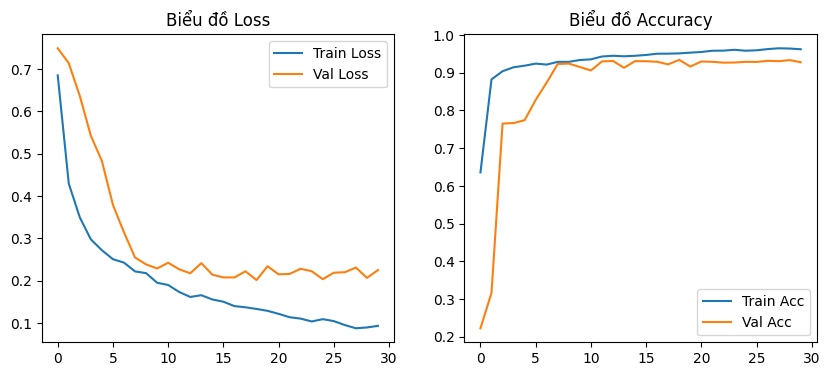

In [18]:
# ==================================================
# 📊 VẼ ĐỒ THỊ LOSS / ACCURACY
# ==================================================
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Biểu đồ Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Biểu đồ Accuracy')
plt.legend()

plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


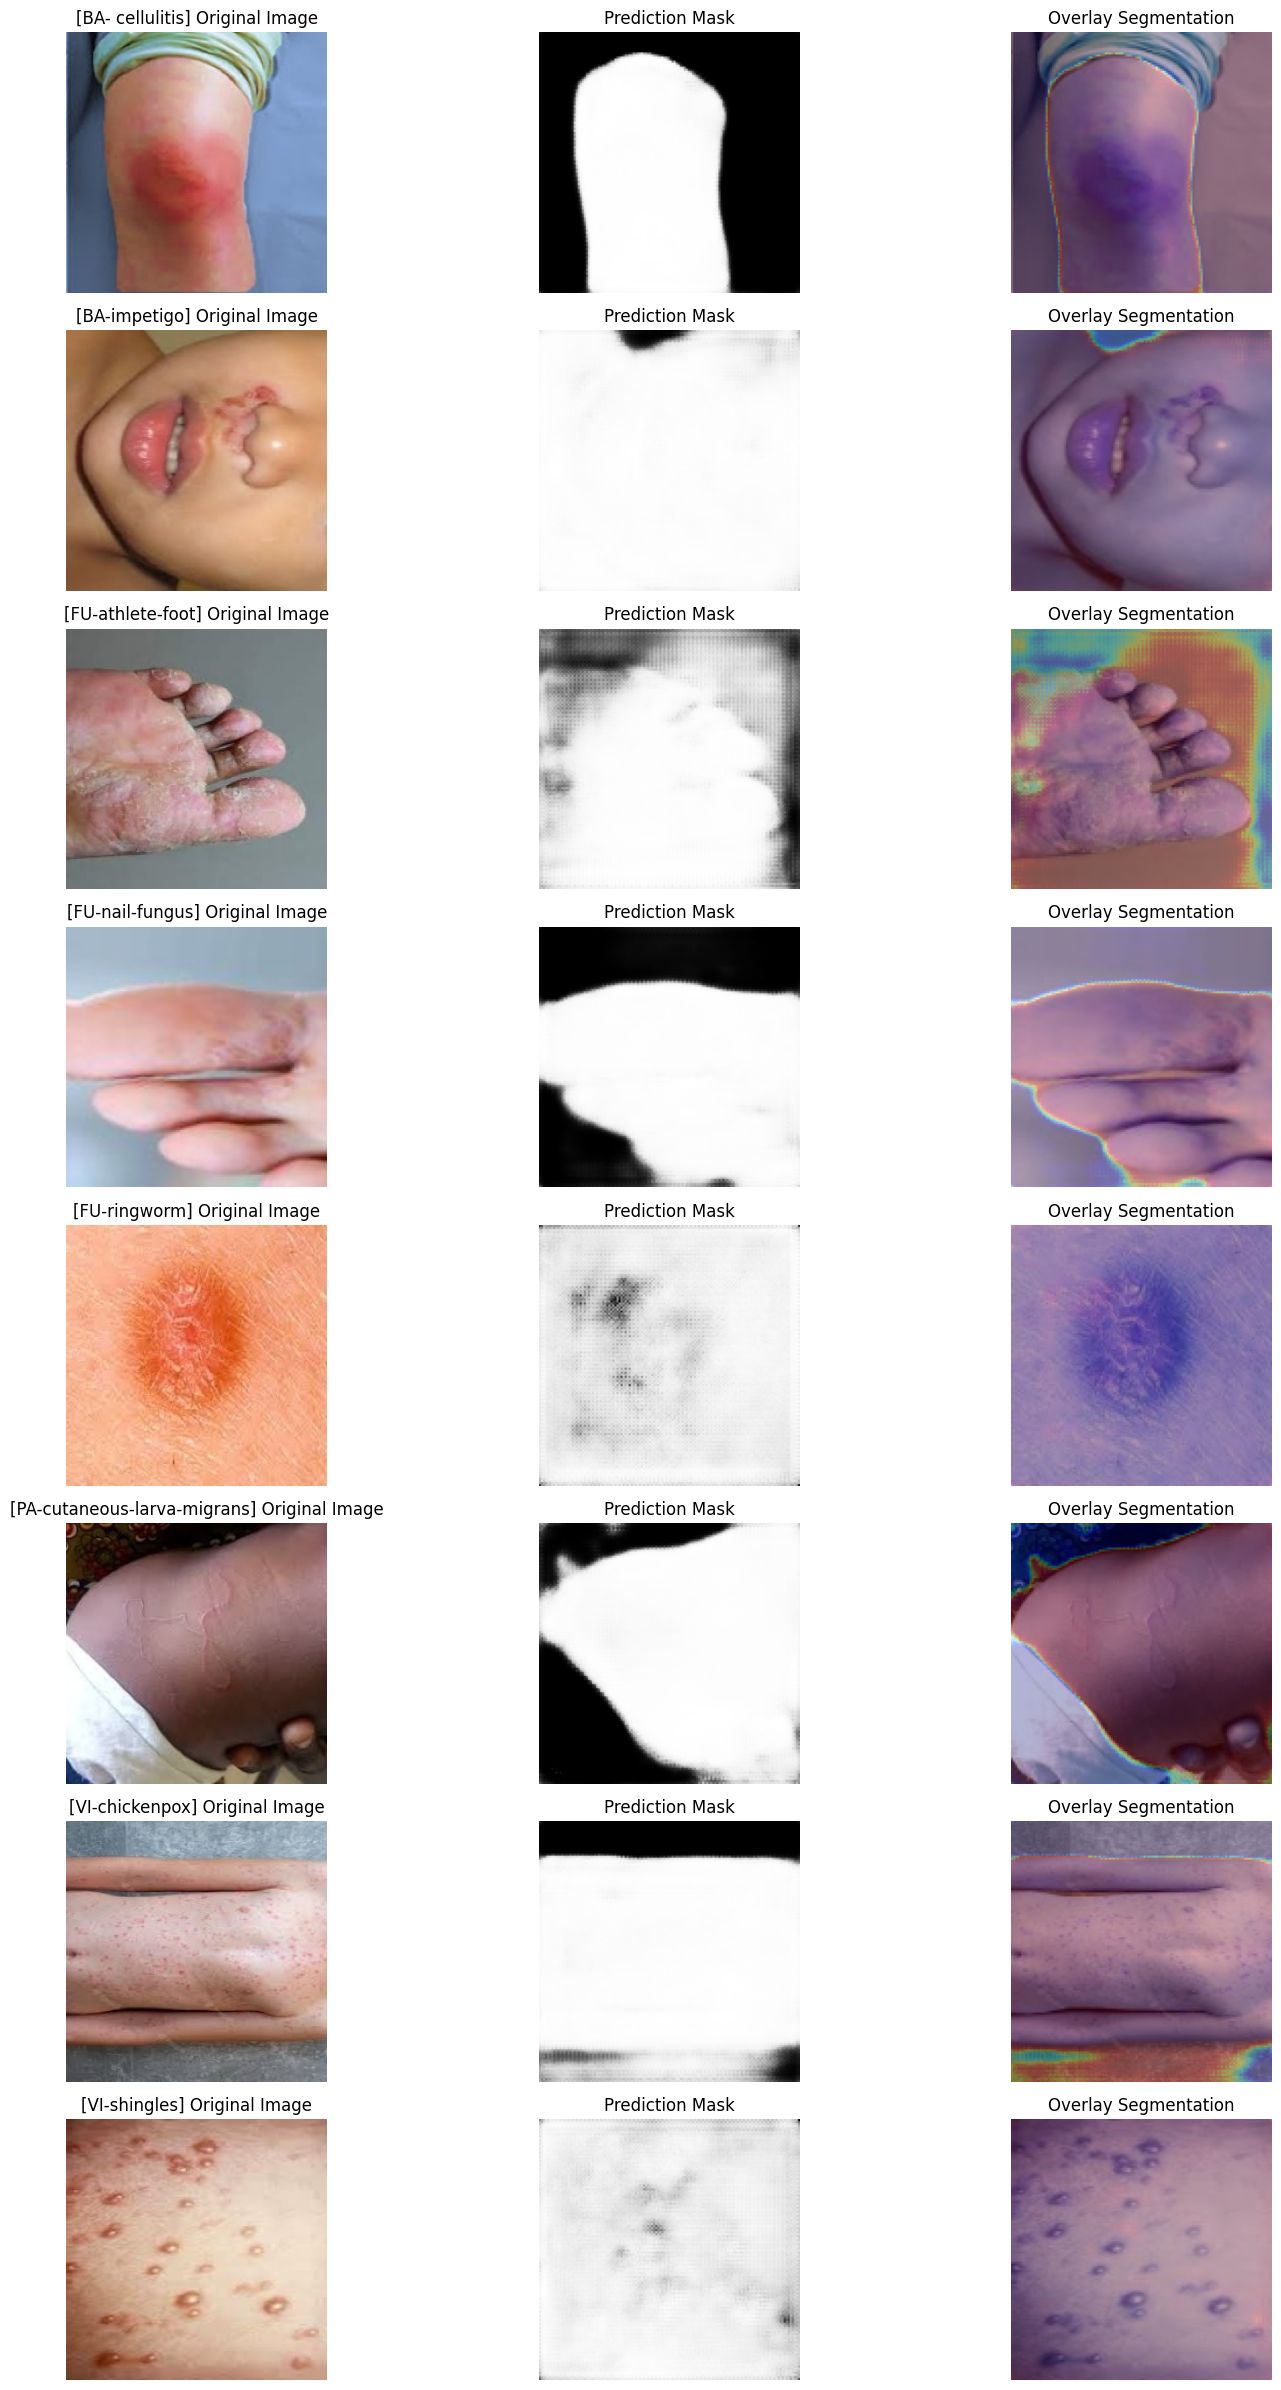

In [19]:
# ==================================================
# 6️⃣ ĐÁNH GIÁ MÔ HÌNH + HIỂN THỊ KẾT QUẢ PHÂN ĐOẠN
# ==================================================
import random
plt.figure(figsize=(16, len(sample_per_class) * 3))
i = 0
for class_name, img_path in sample_per_class.items():
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    resized_img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE)) / 255.0

    pred = model.predict(np.expand_dims(resized_img, axis=0))[0]
    pred_overlay = (pred.squeeze() * 255).astype(np.uint8)
    overlay_color = cv2.applyColorMap(pred_overlay, cv2.COLORMAP_JET)
    overlay_color = cv2.cvtColor(overlay_color, cv2.COLOR_BGR2RGB)
    blended = cv2.addWeighted((resized_img * 255).astype(np.uint8), 0.7, overlay_color, 0.3, 0)

    plt.subplot(len(sample_per_class), 3, i * 3 + 1)
    plt.imshow(img_rgb)
    plt.title(f"[{class_name}] Original Image")
    plt.axis("off")

    plt.subplot(len(sample_per_class), 3, i * 3 + 2)
    plt.imshow(pred.squeeze(), cmap='gray')
    plt.title("Prediction Mask")
    plt.axis("off")

    plt.subplot(len(sample_per_class), 3, i * 3 + 3)
    plt.imshow(blended)
    plt.title("Overlay Segmentation")
    plt.axis("off")

    i += 1

plt.tight_layout()
plt.show()

6/6 ━━━━━━━━━━━━━━━━━━━━ 11s 688ms/step

===== FULL SEGMENTATION REPORT =====
Train: 684, Val: 172
Image Size: 128x128
Epochs: 30, Batch Size: 8
Training Time: 225.73 giây (3.76 phút)
Accuracy : 0.9341
Precision: 0.9506
Recall   : 0.9648
F1-score : 0.9577
Dice     : 0.9577
IoU      : 0.9188


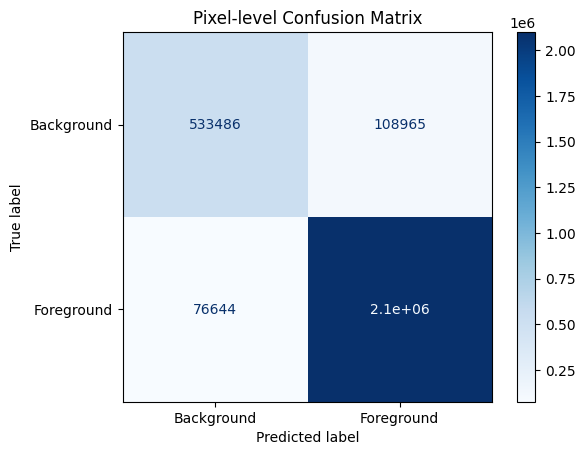

In [20]:
# ==================================================
# 7️⃣ FULL REPORT METRICS
# ==================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Dự đoán mask trên tập validation
Y_pred = model.predict(X_val)
Y_pred_bin = (Y_pred > 0.5).astype(np.uint8)

# Flatten và convert sang int
y_true_flat = (Y_val.flatten() > 0.5).astype(np.uint8)
y_pred_flat = (Y_pred_bin.flatten()).astype(np.uint8)


acc = accuracy_score(y_true_flat, y_pred_flat)
prec = precision_score(y_true_flat, y_pred_flat)
rec = recall_score(y_true_flat, y_pred_flat)
f1 = f1_score(y_true_flat, y_pred_flat)


# Dice & IoU
def dice_coef_np(y_true, y_pred, smooth=1e-6):
    intersection = np.sum(y_true * y_pred)
    return (2. * intersection + smooth) / (np.sum(y_true) + np.sum(y_pred) + smooth)

def iou_score_np(y_true, y_pred, smooth=1e-6):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

dice = dice_coef_np(y_true_flat, y_pred_flat)
iou = iou_score_np(y_true_flat, y_pred_flat)

# --- In báo cáo ---
print("\n===== FULL SEGMENTATION REPORT =====")
print(f"Train: {X_train.shape[0]}, Val: {X_val.shape[0]}")
print(f"Image Size: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"Epochs: {EPOCHS}, Batch Size: {BATCH_SIZE}")
print(f"Training Time: {train_time:.2f} giây ({train_time/60:.2f} phút)")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"Dice     : {dice:.4f}")
print(f"IoU      : {iou:.4f}")

# --- Confusion Matrix ---
cm = confusion_matrix(y_true_flat, y_pred_flat)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Background", "Foreground"])
disp.plot(cmap='Blues')
plt.title("Pixel-level Confusion Matrix")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


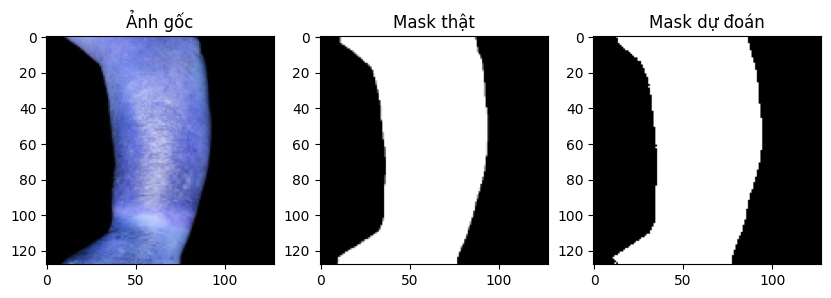

In [36]:
# ==================================================
# 🔍 DỰ ĐOÁN VÀ HIỂN THỊ MỘT ẢNH THỬ
# ==================================================
idx = random.randint(0, len(X_val) - 1)
test_img = X_val[idx]
true_mask = Y_val[idx]

pred_mask = model.predict(test_img[np.newaxis, ...])[0]
pred_mask = (pred_mask > 0.5).astype(np.uint8)

plt.figure(figsize=(10,4))
plt.subplot(1,3,1)
plt.imshow(test_img)
plt.title("Ảnh gốc")

plt.subplot(1,3,2)
plt.imshow(true_mask[...,0], cmap='gray')
plt.title("Mask thật")

plt.subplot(1,3,3)
plt.imshow(pred_mask[...,0], cmap='gray')
plt.title("Mask dự đoán")

plt.show()


🔎 Tìm thấy 924 ảnh để dự đoán.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


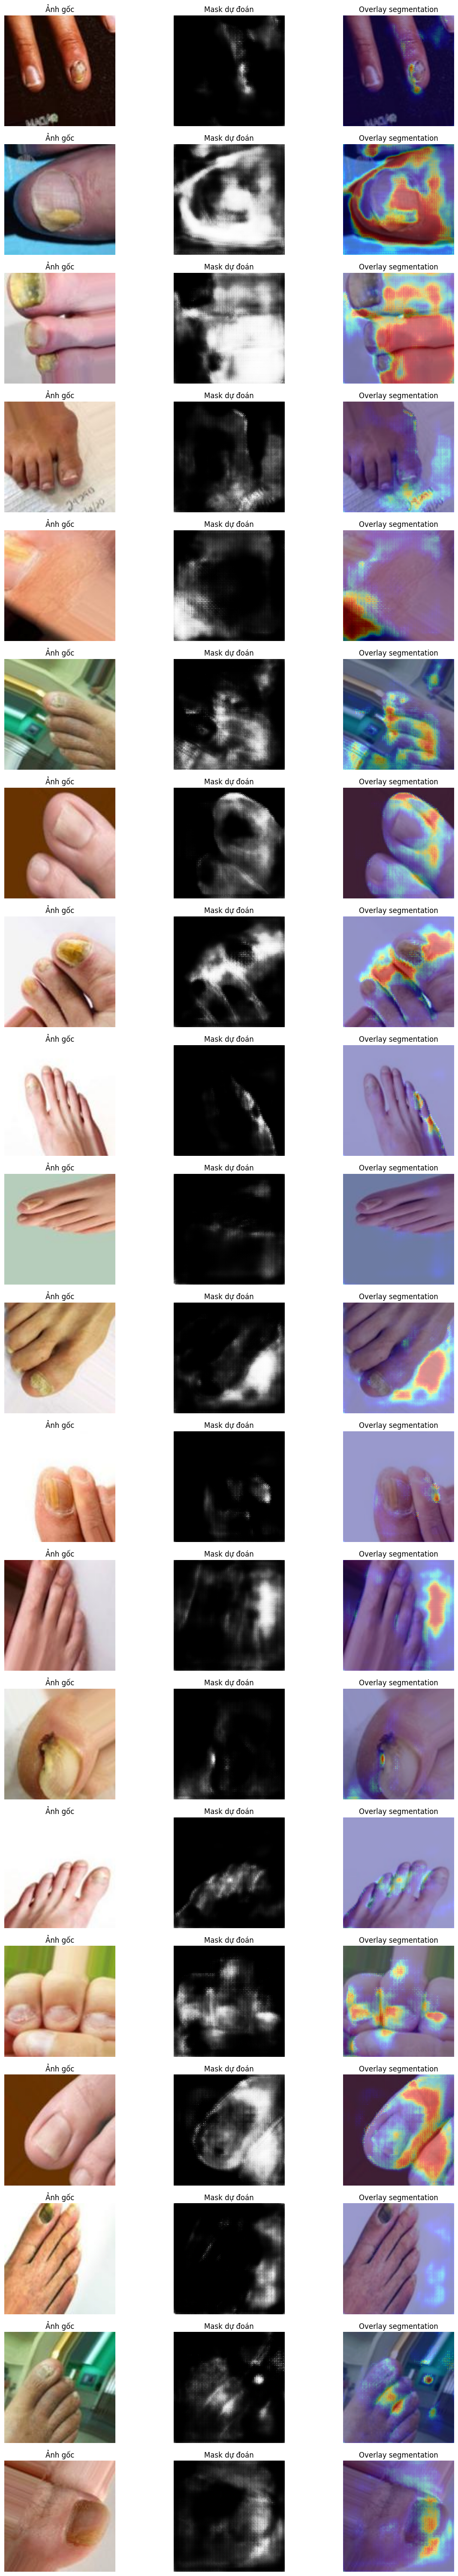

In [54]:
#========================================
# ==================================================
# 🔍 TEST TRÊN TẬP ẢNH KHÔNG CÓ MASK
# ==================================================

TEST_DIR = "/content/skin-disease-datasaet/train_set"
IMAGE_SIZE = 128

test_images = glob(os.path.join(TEST_DIR, "**", "*.*"), recursive=True)
test_images = [f for f in test_images if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

print(f"\n🔎 Tìm thấy {len(test_images)} ảnh để dự đoán.")

plt.figure(figsize=(12, len(test_images) * 3))

for i, img_path in enumerate(test_images[:20]):   # lấy 20 ảnh đầu → tránh quá nhiều
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    resized_img = cv2.resize(img_rgb, (IMAGE_SIZE, IMAGE_SIZE)) / 255.0

    # Dự đoán mask
    pred = model.predict(np.expand_dims(resized_img, axis=0))[0]
    pred_mask = (pred.squeeze() * 255).astype(np.uint8)

    # Overlay màu
    heatmap = cv2.applyColorMap(pred_mask, cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    blended = cv2.addWeighted((resized_img * 255).astype(np.uint8), 0.6, heatmap, 0.4, 0)

    # --- Hiển thị ---
    plt.subplot(len(test_images), 3, i * 3 + 1)
    plt.imshow(img_rgb)
    plt.title("Ảnh gốc")
    plt.axis("off")

    plt.subplot(len(test_images), 3, i * 3 + 2)
    plt.imshow(pred.squeeze(), cmap='gray')
    plt.title("Mask dự đoán")
    plt.axis("off")

    plt.subplot(len(test_images), 3, i * 3 + 3)
    plt.imshow(blended)
    plt.title("Overlay segmentation")
    plt.axis("off")

plt.tight_layout()
plt.show()